In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q pyedflib scipy numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 43.4 MB/s eta 0:00:00


In [3]:
import zipfile
import os

ZIP_PATH = '/content/drive/MyDrive/eeg-motor-movementimagery-dataset-1.0.0.zip'

EXTRACT_PATH = '/content/eegmmidb_raw'
os.makedirs(EXTRACT_PATH, exist_ok=True)

if not os.path.exists(ZIP_PATH):
    print('ZIP_PATH NOT EXIST:', ZIP_PATH)
    print('Look at the Folder in drive and update it')
else:
    print('Zip mil gayi, extract ho rahi hai... (thoda time lagega)')
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)
    print('✅ Extraction complete!')

Zip mil gayi, extract ho rahi hai... (thoda time lagega)
✅ Extraction complete!


In [4]:
DATASET_PATH = None
for root, dirs, files in os.walk(EXTRACT_PATH):
    if 'S001' in dirs:
        DATASET_PATH = root
        break

if DATASET_PATH is None:
    print('❌ S001 folder not found:')
    for root, dirs, files in os.walk(EXTRACT_PATH):
        level = root.replace(EXTRACT_PATH, '').count(os.sep)
        indent = '  ' * level
        print(f'{indent}{os.path.basename(root)}/')
        if level < 2:
            for d in dirs[:10]:
                print(f'{indent}  {d}/')
else:
    print('DATASET_PATH auto-detected:', DATASET_PATH)
    subject_folders = sorted([d for d in os.listdir(DATASET_PATH) if d.startswith('S')])
    print('Total subject folders mile:', len(subject_folders))
    print('Sample:', subject_folders[:5], '...', subject_folders[-3:])

    sample_files = sorted(os.listdir(os.path.join(DATASET_PATH, 'S001')))
    print('\nFiles in S001:')
    for f in sample_files:
        print(' -', f)

DATASET_PATH auto-detected: /content/eegmmidb_raw/files
Total subject folders mile: 110
Sample: ['S001', 'S002', 'S003', 'S004', 'S005'] ... ['S108', 'S109', 'SHA256SUMS.txt']

Files in S001:
 - S001R01.edf
 - S001R01.edf.event
 - S001R02.edf
 - S001R02.edf.event
 - S001R03.edf
 - S001R03.edf.event
 - S001R04.edf
 - S001R04.edf.event
 - S001R05.edf
 - S001R05.edf.event
 - S001R06.edf
 - S001R06.edf.event
 - S001R07.edf
 - S001R07.edf.event
 - S001R08.edf
 - S001R08.edf.event
 - S001R09.edf
 - S001R09.edf.event
 - S001R10.edf
 - S001R10.edf.event
 - S001R11.edf
 - S001R11.edf.event
 - S001R12.edf
 - S001R12.edf.event
 - S001R13.edf
 - S001R13.edf.event
 - S001R14.edf
 - S001R14.edf.event


In [5]:
NUM_CLASSES = 4
REQUIRED_RUNS = [1, 4, 6, 8, 10, 12, 14]  # baseline + all MI runs needed for 4-class

subject_ids_all = sorted(int(d[1:]) for d in os.listdir(DATASET_PATH) if d.startswith('S') and d[1:].isdigit())

missing_report = {}
valid_subjects = []

for sid in subject_ids_all:
    folder = os.path.join(DATASET_PATH, 'S%03d' % sid)
    missing = []
    for run in REQUIRED_RUNS:
        fname = 'S%03dR%02d.edf' % (sid, run)
        if not os.path.exists(os.path.join(folder, fname)):
            missing.append(fname)
    if missing:
        missing_report[sid] = missing
    else:
        valid_subjects.append(sid)
print(f'Total subjects found: {len(subject_ids_all)}')
print(f'Fully valid subjects (saari required files maujood): {len(valid_subjects)}')
print(f'Subjects with missing files: {len(missing_report)}')
if missing_report:
    print('\nFirst 5 subjects whose files are missing (sample):')
    for sid in list(missing_report.keys())[:5]:
        print(f'  S{sid:03d}: missing ->', missing_report[sid])

SUBJECT_IDS = valid_subjects  # sirf wahi subjects process honge jinki saari files maujood hain

Total subjects found: 109
Fully valid subjects (saari required files maujood): 109
Subjects with missing files: 0


In [6]:
SAVE_DIR = '/content/drive/MyDrive/EEG_Extracted/20-Subjects'
os.makedirs(SAVE_DIR, exist_ok=True)
print('Output saved here:', SAVE_DIR)
print('Total subjects process :', len(SUBJECT_IDS))

Output saved here: /content/drive/MyDrive/EEG_Extracted/20-Subjects
Total subjects process : 109


In [7]:
import numpy as np
import pyedflib

SAMPLE_RATE = 160
EEG_CHANNELS = 64
BASELINE_RUN = 1
MI_RUNS = [4, 8, 12]
if NUM_CLASSES >= 4:
    MI_RUNS = MI_RUNS + [6, 10, 14]

RUN_LENGTH = 125 * SAMPLE_RATE
TRIAL_LENGTH = 4  # seconds
NUM_TRIALS = 21 * NUM_CLASSES


def edf_path(subject_id, run):
    folder = 'S%03d' % subject_id
    fname = 'S%03dR%02d.edf' % (subject_id, run)
    return os.path.join(DATASET_PATH, folder, fname)


def load_edf_signals(path):
    sig = pyedflib.EdfReader(path)
    n = sig.signals_in_file
    sigbuf = np.zeros((n, sig.getNSamples()[0]))
    for j in range(n):
        sigbuf[j, :] = sig.readSignal(j)
    onsets, durations, descriptions = sig.readAnnotations()
    annotations = list(zip(onsets, durations, descriptions))
    sig._close()
    del sig
    return sigbuf.transpose(), annotations


def load_physionet_subject(subject_id, num_classes=4):
    n_runs = len(MI_RUNS)
    X = np.zeros((n_runs, RUN_LENGTH, EEG_CHANNELS))
    events = []

    for i_run, current_run in enumerate(MI_RUNS):
        path = edf_path(subject_id, current_run)
        signals, annotations = load_edf_signals(path)
        X[i_run, :signals.shape[0], :] = signals

        current_event = [i_run, 0, 0, 0]
        for annotation in annotations:
            t = int(annotation[0] * SAMPLE_RATE)
            action = int(annotation[2][1])

            if action == 0 and current_event[1] != 0:
                length = TRIAL_LENGTH * SAMPLE_RATE
                pad = (length - (t - current_event[2])) // 2
                current_event[2] -= pad + (t - current_event[2]) % 2
                current_event[3] = t + pad
                if (current_run - 6) % 4 != 0 or current_event[1] == 2:
                    if (current_run - 6) % 4 == 0:
                        current_event[1] = 3
                    events.append(current_event)
            elif action > 0:
                current_event = [i_run, action, t, 0]

    num_mi_trials = len(events)
    trials = np.zeros((NUM_TRIALS, TRIAL_LENGTH * SAMPLE_RATE, EEG_CHANNELS))
    labels = np.zeros((NUM_TRIALS, num_classes))

    for i, ev in enumerate(events):
        trials[i, :, :] = X[ev[0], ev[2]:ev[3]]
        labels[i, ev[1] - 1] = 1.

    if num_classes >= 3:
        path = edf_path(subject_id, BASELINE_RUN)
        signals, annotations = load_edf_signals(path)
        SAMPLES = TRIAL_LENGTH * SAMPLE_RATE
        for i in range(num_mi_trials, NUM_TRIALS):
            offset = np.random.randint(0, signals.shape[0] - SAMPLES)
            trials[i, :, :] = signals[offset:offset + SAMPLES, :]
            labels[i, -1] = 1.

    return trials, labels


print('Functions ready.')

Functions ready.


In [8]:
all_trials = []
all_labels = []
good_subjects = []
failed_subjects = {}

for sid in SUBJECT_IDS:
    try:
        trials, labels = load_physionet_subject(sid, num_classes=NUM_CLASSES)
        all_trials.append(trials)
        all_labels.append(labels)
        good_subjects.append(sid)
        print(f'Subject {sid:03d} loaded OK  -> trials shape {trials.shape}')
    except Exception as e:
        failed_subjects[sid] = str(e)
        print(f'Subject {sid:03d} FAILED: {e}')

print('\nDone.')
print('Successful subjects:', len(good_subjects), '/', len(SUBJECT_IDS))
if failed_subjects:
    print('Failed subjects:', list(failed_subjects.keys()))

if good_subjects:
    all_trials = np.array(all_trials)
    all_labels = np.array(all_labels)
    print('all_trials shape:', all_trials.shape)
    print('all_labels shape:', all_labels.shape)
else:
    print('no subject loaded.')

Subject 001 loaded OK  -> trials shape (84, 640, 64)
Subject 002 loaded OK  -> trials shape (84, 640, 64)
Subject 003 loaded OK  -> trials shape (84, 640, 64)
Subject 004 loaded OK  -> trials shape (84, 640, 64)
Subject 005 loaded OK  -> trials shape (84, 640, 64)
Subject 006 loaded OK  -> trials shape (84, 640, 64)
Subject 007 loaded OK  -> trials shape (84, 640, 64)
Subject 008 loaded OK  -> trials shape (84, 640, 64)
Subject 009 loaded OK  -> trials shape (84, 640, 64)
Subject 010 loaded OK  -> trials shape (84, 640, 64)
Subject 011 loaded OK  -> trials shape (84, 640, 64)
Subject 012 loaded OK  -> trials shape (84, 640, 64)
Subject 013 loaded OK  -> trials shape (84, 640, 64)
Subject 014 loaded OK  -> trials shape (84, 640, 64)
Subject 015 loaded OK  -> trials shape (84, 640, 64)
Subject 016 loaded OK  -> trials shape (84, 640, 64)
Subject 017 loaded OK  -> trials shape (84, 640, 64)
Subject 018 loaded OK  -> trials shape (84, 640, 64)
Subject 019 loaded OK  -> trials shape (84, 64

In [9]:
import scipy.io as sio

assert len(good_subjects) > 0, 'Koi data nahi hai save karne ke liye — Cell 8 ka error check karein.'

for e in range(EEG_CHANNELS):
    X_e = all_trials[:, :, :, e]
    sio.savemat(os.path.join(SAVE_DIR, f'Dataset_{e+1}.mat'), {'Dataset': X_e})
    sio.savemat(os.path.join(SAVE_DIR, f'Labels_{e+1}.mat'), {'Labels': all_labels})
    if (e + 1) % 8 == 0 or e == EEG_CHANNELS - 1:
        print(f'Saved electrode {e+1}/{EEG_CHANNELS}')

print('\n✅ All electrode files saved to:', SAVE_DIR)

Saved electrode 8/64
Saved electrode 16/64
Saved electrode 24/64
Saved electrode 32/64
Saved electrode 40/64
Saved electrode 48/64
Saved electrode 56/64
Saved electrode 64/64

✅ All electrode files saved to: /content/drive/MyDrive/EEG_Extracted/20-Subjects


In [10]:
check = sio.loadmat(os.path.join(SAVE_DIR, 'Dataset_1.mat'))
check_labels = sio.loadmat(os.path.join(SAVE_DIR, 'Labels_1.mat'))
print('Dataset_1.mat shape:', check['Dataset'].shape)
print('Labels_1.mat shape:', check_labels['Labels'].shape)

Dataset_1.mat shape: (109, 84, 640)
Labels_1.mat shape: (109, 84, 4)


In [11]:
import os

# Jahan Dataset_*.mat aur Labels_*.mat files pehle se save hain (extraction notebook wala SAVE_DIR)
MAT_DIR = '/content/drive/MyDrive/EEG_Extracted/20-Subjects'

# Final CSV files yahan save hongi
OUT_DIR = '/content/drive/MyDrive/EEG_Extracted/CNN_Preprocessed'
os.makedirs(OUT_DIR, exist_ok=True)

if not os.path.exists(os.path.join(MAT_DIR, 'Dataset_1.mat')):
    print('❌ Dataset_1.mat nahi mili is path pe:', MAT_DIR)
    print('MAT_DIR ko apne extraction wale SAVE_DIR se match karein.')
else:
    print('✅ Files mil gayi. Aage badhein.')

✅ Files mil gayi. Aage badhein.


In [12]:
import numpy as np
import scipy.io as sio

EEG_CHANNELS = 64

electrode_arrays = []
for e in range(1, EEG_CHANNELS + 1):
    d = sio.loadmat(os.path.join(MAT_DIR, f'Dataset_{e}.mat'))['Dataset']
    electrode_arrays.append(d)

# Shape: (n_subjects, n_trials, n_samples, 64)
all_trials = np.stack(electrode_arrays, axis=-1)

labels_mat = sio.loadmat(os.path.join(MAT_DIR, 'Labels_1.mat'))['Labels']  # (n_subjects, n_trials, n_classes)

print('all_trials shape:', all_trials.shape)
print('labels shape:', labels_mat.shape)

all_trials shape: (109, 84, 640, 64)
labels shape: (109, 84, 4)


In [13]:
TIME_POINTS = 64

n_subjects, n_trials, n_samples, n_channels = all_trials.shape
window = n_samples // TIME_POINTS
print(f'Har channel ke {n_samples} samples ko {TIME_POINTS} time-points mein convert kiya ja raha hai (window size = {window})')

trimmed = all_trials[:, :, :window * TIME_POINTS, :]
downsampled = trimmed.reshape(n_subjects, n_trials, TIME_POINTS, window, n_channels).mean(axis=3)
# downsampled shape: (n_subjects, n_trials, 64 time-points, 64 channels)

print('downsampled shape:', downsampled.shape)

Har channel ke 640 samples ko 64 time-points mein convert kiya ja raha hai (window size = 10)
downsampled shape: (109, 84, 64, 64)


In [14]:
# channel-major order: [ch0_t0..ch0_t63, ch1_t0..ch1_t63, ...]
X = downsampled.transpose(0, 1, 3, 2)               # -> (subjects, trials, channels, time)
X = X.reshape(n_subjects * n_trials, EEG_CHANNELS * TIME_POINTS)   # -> (samples, 4096)

# One-hot labels -> integer class (0,1,2,3) jaisa README mein zaroori bataya gaya hai
y_onehot = labels_mat.reshape(n_subjects * n_trials, -1)
y = np.argmax(y_onehot, axis=1)

print('X shape:', X.shape)
print('y shape:', y.shape)
print('Class distribution:', np.bincount(y))

X shape: (9156, 4096)
y shape: (9156,)
Class distribution: [2296 2295 2296 2269]


In [15]:
rng = np.random.RandomState(42)
idx = rng.permutation(len(X))
X, y = X[idx], y[idx]

split = int(len(X) * 0.9)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print('Training samples:', X_train.shape[0])
print('Test samples:', X_test.shape[0])

Training samples: 8240
Test samples: 916


In [16]:
import pandas as pd

pd.DataFrame(X_train).to_csv(os.path.join(OUT_DIR, 'training_set.csv'), header=False, index=False)
pd.DataFrame(X_test).to_csv(os.path.join(OUT_DIR, 'test_set.csv'), header=False, index=False)
pd.DataFrame(y_train).to_csv(os.path.join(OUT_DIR, 'training_label.csv'), header=False, index=False)
pd.DataFrame(y_test).to_csv(os.path.join(OUT_DIR, 'test_label.csv'), header=False, index=False)

print('✅ Saari CSV files save ho gayi:', OUT_DIR)
print(' - training_set.csv  :', X_train.shape)
print(' - training_label.csv:', y_train.shape)
print(' - test_set.csv       :', X_test.shape)
print(' - test_label.csv     :', y_test.shape)

✅ Saari CSV files save ho gayi: /content/drive/MyDrive/EEG_Extracted/CNN_Preprocessed
 - training_set.csv  : (8240, 4096)
 - training_label.csv: (8240,)
 - test_set.csv       : (916, 4096)
 - test_label.csv     : (916,)


In [17]:
check = pd.read_csv(os.path.join(OUT_DIR, 'training_set.csv'), header=None)
check_label = pd.read_csv(os.path.join(OUT_DIR, 'training_label.csv'), header=None)
print('training_set.csv shape:', check.shape, '(zaroori: columns = 4096)')
print('training_label.csv shape:', check_label.shape)
print('Label unique values:', sorted(check_label[0].unique()))

training_set.csv shape: (8240, 4096) (zaroori: columns = 4096)
training_label.csv shape: (8240, 1)
Label unique values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [18]:
import tensorflow.compat.v1 as tf
tf.disable_v2_behavior()
import numpy as np
import pandas as pd
import random
import os
import matplotlib.pyplot as plt

print('TensorFlow version:', tf.__version__)
print('GPU available:', tf.test.is_gpu_available())

Instructions for updating:
non-resource variables are not supported in the long term
Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


TensorFlow version: 2.20.0
GPU available: True


In [19]:
import os # Added for os.makedirs and os.path.exists

# Jahan Cell 7 (preprocessing notebook) ne CSV files save ki thi
DIR = '/content/drive/MyDrive/EEG_Extracted/CNN_Preprocessed/' # Re-enabled definition in this cell

# Trained model aur results yahan save honge
SAVE = '/content/drive/MyDrive/EEG_Extracted/Saved_Model_CNN/'
os.makedirs(SAVE, exist_ok=True)

required_files = ['training_set.csv', 'training_label.csv', 'test_set.csv', 'test_label.csv']
missing = [f for f in required_files if not os.path.exists(os.path.join(DIR, f))]
if missing:
    print('❌ Yeh files nahi milin:', missing)
    print('DIR path check karein:', DIR)
else:
    print('✅ All the saved files are available.')

✅ All the saved files are available.


In [20]:
import tensorflow.compat.v1 as tf

def weight_variable(shape):
    initial = tf.truncated_normal(shape, stddev=0.1)
    return tf.Variable(initial)


def bias_variable(shape):
    initial = tf.constant(0.1, shape=shape)
    return tf.Variable(initial)


def manual_batch_norm(inputs, training, scope_name):
    with tf.variable_scope(scope_name, reuse=tf.AUTO_REUSE):
        num_channels = inputs.shape[-1]

        gamma = tf.get_variable('gamma', shape=[num_channels], initializer=tf.constant_initializer(1.0))
        beta = tf.get_variable('beta', shape=[num_channels], initializer=tf.constant_initializer(0.0))

        moving_mean = tf.get_variable('moving_mean', shape=[num_channels],
                                      initializer=tf.constant_initializer(0.0),
                                      trainable=False)
        moving_variance = tf.get_variable('moving_variance', shape=[num_channels],
                                          initializer=tf.constant_initializer(1.0),
                                          trainable=False)

        epsilon = 1e-3
        decay = 0.99

        # Determine axes for moments calculation based on input rank
        if len(inputs.shape) == 4: # Conv layer output: [batch, height, width, channels]
            axes = [0, 1, 2]
        elif len(inputs.shape) == 2: # FC layer output: [batch, features]
            axes = [0]
        else:
            raise ValueError("Unsupported input rank for batch normalization.")

        def mean_var_with_update():
            batch_mean, batch_variance = tf.nn.moments(inputs, axes=axes, keepdims=False)

            update_moving_mean = tf.assign(moving_mean, moving_mean * decay + batch_mean * (1 - decay))
            update_moving_variance = tf.assign(moving_variance, moving_variance * decay + batch_variance * (1 - decay))

            # Add update ops to the collection so they are run during training
            tf.add_to_collection(tf.GraphKeys.UPDATE_OPS, update_moving_mean)
            tf.add_to_collection(tf.GraphKeys.UPDATE_OPS, update_moving_variance)

            # Return batch statistics for batch normalization operation
            return tf.identity(batch_mean), tf.identity(batch_variance)

        # Use batch statistics during training, moving averages during inference
        mean, variance = tf.cond(training, mean_var_with_update, lambda: (moving_mean, moving_variance))

        # Perform batch normalization
        return tf.nn.batch_normalization(inputs, mean, variance, beta, gamma, epsilon)


def CNN(Input, keep_prob, training):
    x_Reshape = tf.reshape(Input, [-1, 64, 64, 1])

    # ---------------- Conv1 ----------------
    W_conv1 = weight_variable([3, 3, 1, 32])
    b_conv1 = bias_variable([32])

    h_conv1 = tf.nn.conv2d(
        x_Reshape,
        W_conv1,
        strides=[1, 1, 1, 1],
        padding="SAME"
    ) + b_conv1

    h_conv1 = tf.nn.leaky_relu(h_conv1)

    h_conv1_drop = tf.nn.dropout(
        h_conv1,
        keep_prob,
        noise_shape=[
            tf.shape(h_conv1)[0],
            1,
            1,
            tf.shape(h_conv1)[3]
        ]
    )

    # ---------------- Conv2 ----------------
    W_conv2 = weight_variable([3, 3, 32, 32])
    b_conv2 = bias_variable([32])

    h_conv2 = tf.nn.conv2d(
        h_conv1_drop,
        W_conv2,
        strides=[1, 1, 1, 1],
        padding="SAME"
    ) + b_conv2

    h_conv2 = manual_batch_norm(h_conv2, training, 'conv2_bn')
    h_conv2 = tf.nn.leaky_relu(h_conv2)

    # ---------------- Conv3 ----------------
    W_conv3 = weight_variable([3, 3, 64, 64])
    b_conv3 = bias_variable([64])

    h_conv3_res = tf.concat([h_conv2, h_conv1_drop], axis=3)

    h_conv3 = tf.nn.conv2d(
        h_conv3_res,
        W_conv3,
        strides=[1, 1, 1, 1],
        padding="SAME"
    ) + b_conv3

    h_conv3 = tf.nn.leaky_relu(h_conv3)

    h_conv3_drop = tf.nn.dropout(
        h_conv3,
        keep_prob,
        noise_shape=[
            tf.shape(h_conv3)[0],
            1,
            1,
            tf.shape(h_conv3)[3]
        ]
    )

    # ---------------- Pool1 ----------------
    h_pool3 = tf.nn.max_pool(
        h_conv3_drop,
        ksize=[1, 2, 2, 1],
        strides=[1, 2, 2, 1],
        padding="SAME"
    )

    # ---------------- Conv4 ----------------
    W_conv4 = weight_variable([3, 3, 64, 64])
    b_conv4 = bias_variable([64])

    h_conv4 = tf.nn.conv2d(
        h_pool3,
        W_conv4,
        strides=[1, 1, 1, 1],
        padding="VALID"
    ) + b_conv4

    h_conv4 = manual_batch_norm(h_conv4, training, 'conv4_bn')
    h_conv4 = tf.nn.leaky_relu(h_conv4)

    h_conv4_drop = tf.nn.dropout(
        h_conv4,
        keep_prob,
        noise_shape=[
            tf.shape(h_conv4)[0],
            1,
            1,
            tf.shape(h_conv4)[3]
        ]
    )

    # ---------------- Conv5 ----------------
    W_conv5 = weight_variable([3, 3, 64, 64])
    b_conv5 = bias_variable([64])

    h_conv5 = tf.nn.conv2d(
        h_conv4_drop,
        W_conv5,
        strides=[1, 1, 1, 1],
        padding="SAME"
    ) + b_conv5

    h_conv5 = manual_batch_norm(h_conv5, training, 'conv5_bn')
    h_conv5 = tf.nn.leaky_relu(h_conv5)

    # ---------------- Conv6 ----------------
    W_conv6 = weight_variable([3, 3, 128, 128])
    b_conv6 = bias_variable([128])

    h_conv6_res = tf.concat([h_conv5, h_conv4_drop], axis=3)

    h_conv6 = tf.nn.conv2d(
        h_conv6_res,
        W_conv6,
        strides=[1, 1, 1, 1],
        padding="SAME"
    ) + b_conv6

    h_conv6 = tf.nn.leaky_relu(h_conv6)

    h_conv6_drop = tf.nn.dropout(
        h_conv6,
        keep_prob,
        noise_shape=[
            tf.shape(h_conv6)[0],
            1,
            1,
            tf.shape(h_conv6)[3]
        ]
    )
    # ---------------- Pool2 ----------------
    h_pool6 = tf.nn.max_pool(
        h_conv6_drop,
        ksize=[1, 2, 2, 1],
        strides=[1, 2, 2, 1],
        padding="SAME"
    )

    # ---------------- Flatten ----------------
    h_pool6_flat = tf.reshape(h_pool6, [-1, 15 * 15 * 128])

    # ---------------- FC1 ----------------
    W_fc1 = weight_variable([15 * 15 * 128, 512])
    b_fc1 = bias_variable([512])

    h_fc1 = tf.matmul(h_pool6_flat, W_fc1) + b_fc1

    h_fc1 = manual_batch_norm(h_fc1, training, 'fc1_bn')
    h_fc1 = tf.nn.leaky_relu(h_fc1)

    h_fc1_drop = tf.nn.dropout(h_fc1, keep_prob)

    # ---------------- Output ----------------
    W_fc2 = weight_variable([512, 4])
    b_fc2 = bias_variable([4])

    prediction = tf.nn.softmax(
        tf.matmul(h_fc1_drop, W_fc2) + b_fc2
    )

    return prediction
print("CNN architecture defined.")

CNN architecture defined.


In [21]:
import inspect
print(inspect.getsource(CNN))

def CNN(Input, keep_prob, training):
    x_Reshape = tf.reshape(Input, [-1, 64, 64, 1])

    # ---------------- Conv1 ----------------
    W_conv1 = weight_variable([3, 3, 1, 32])
    b_conv1 = bias_variable([32])

    h_conv1 = tf.nn.conv2d(
        x_Reshape,
        W_conv1,
        strides=[1, 1, 1, 1],
        padding="SAME"
    ) + b_conv1

    h_conv1 = tf.nn.leaky_relu(h_conv1)

    h_conv1_drop = tf.nn.dropout(
        h_conv1,
        keep_prob,
        noise_shape=[
            tf.shape(h_conv1)[0],
            1,
            1,
            tf.shape(h_conv1)[3]
        ]
    )

    # ---------------- Conv2 ----------------
    W_conv2 = weight_variable([3, 3, 32, 32])
    b_conv2 = bias_variable([32])

    h_conv2 = tf.nn.conv2d(
        h_conv1_drop,
        W_conv2,
        strides=[1, 1, 1, 1],
        padding="SAME"
    ) + b_conv2

    h_conv2 = manual_batch_norm(h_conv2, training, 'conv2_bn')
    h_conv2 = tf.nn.leaky_relu(h_conv2)

    # ---------------- Conv3 -------

In [22]:
import tensorflow.compat.v1 as tf
tf.disable_v2_behavior()

def weight_variable(shape):
    initial = tf.truncated_normal(shape, stddev=0.1)
    return tf.Variable(initial)

def bias_variable(shape):
    initial = tf.constant(0.1, shape=shape)
    return tf.Variable(initial)

# Manual Batch Normalization -- Keras par depend nahi karta, isliye error nahi aayega
def batch_norm(x, epsilon=1e-3):
    axes = list(range(len(x.shape) - 1))  # sab dims except last (channel dim) par normalize
    mean, var = tf.nn.moments(x, axes=axes, keep_dims=False)
    channels = x.shape[-1]
    scale = tf.Variable(tf.ones([channels]))
    beta = tf.Variable(tf.zeros([channels]))
    return tf.nn.batch_normalization(x, mean, var, beta, scale, epsilon)

def CNN(Input, keep_prob):
    x_Reshape = tf.reshape(tensor=Input, shape=[-1, 64, 64, 1])
    drop_rate = 1 - keep_prob

    W_conv1 = weight_variable([3, 3, 1, 32])
    b_conv1 = bias_variable([32])
    h_conv1 = tf.nn.conv2d(x_Reshape, W_conv1, strides=[1, 1, 1, 1], padding='SAME') + b_conv1
    h_conv1_Acti = tf.nn.leaky_relu(h_conv1)
    h_conv1_drop = tf.nn.dropout(h_conv1_Acti, rate=drop_rate,
                                  noise_shape=[tf.shape(h_conv1_Acti)[0], 1, 1, tf.shape(h_conv1_Acti)[3]])

    W_conv2 = weight_variable([3, 3, 32, 32])
    b_conv2 = bias_variable([32])
    h_conv2 = tf.nn.conv2d(h_conv1_drop, W_conv2, strides=[1, 1, 1, 1], padding='SAME') + b_conv2
    h_conv2_BN = batch_norm(h_conv2)
    h_conv2_Acti = tf.nn.leaky_relu(h_conv2_BN)

    W_conv3 = weight_variable([3, 3, 64, 64])
    b_conv3 = bias_variable([64])
    h_conv3_res = tf.concat([h_conv2_Acti, h_conv1_drop], axis=3)
    h_conv3 = tf.nn.conv2d(h_conv3_res, W_conv3, strides=[1, 1, 1, 1], padding='SAME') + b_conv3
    h_conv3_Acti = tf.nn.leaky_relu(h_conv3)
    h_conv3_drop = tf.nn.dropout(h_conv3_Acti, rate=drop_rate,
                                  noise_shape=[tf.shape(h_conv3_Acti)[0], 1, 1, tf.shape(h_conv3_Acti)[3]])

    h_pool3 = tf.nn.max_pool(h_conv3_drop, ksize=[1, 2, 2, 1], strides=[1, 2, 2, 1], padding='SAME')

    W_conv4 = weight_variable([3, 3, 64, 64])
    b_conv4 = bias_variable([64])
    h_conv4 = tf.nn.conv2d(h_pool3, W_conv4, strides=[1, 1, 1, 1], padding='VALID') + b_conv4
    h_conv4_BN = batch_norm(h_conv4)
    h_conv4_Acti = tf.nn.leaky_relu(h_conv4_BN)
    h_conv4_drop = tf.nn.dropout(h_conv4_Acti, rate=drop_rate,
                                  noise_shape=[tf.shape(h_conv4_Acti)[0], 1, 1, tf.shape(h_conv4_Acti)[3]])

    W_conv5 = weight_variable([3, 3, 64, 64])
    b_conv5 = bias_variable([64])
    h_conv5 = tf.nn.conv2d(h_conv4_drop, W_conv5, strides=[1, 1, 1, 1], padding='SAME') + b_conv5
    h_conv5_BN = batch_norm(h_conv5)
    h_conv5_Acti = tf.nn.leaky_relu(h_conv5_BN)

    W_conv6 = weight_variable([3, 3, 128, 128])
    b_conv6 = bias_variable([128])
    h_conv6_res = tf.concat([h_conv5_Acti, h_conv4_drop], axis=3)
    h_conv6 = tf.nn.conv2d(h_conv6_res, W_conv6, strides=[1, 1, 1, 1], padding='SAME') + b_conv6
    h_conv6_Acti = tf.nn.leaky_relu(h_conv6)
    h_conv6_drop = tf.nn.dropout(h_conv6_Acti, rate=drop_rate,
                                  noise_shape=[tf.shape(h_conv6_Acti)[0], 1, 1, tf.shape(h_conv6_Acti)[3]])

    h_pool6 = tf.nn.max_pool(h_conv6_drop, ksize=[1, 2, 2, 1], strides=[1, 2, 2, 1], padding='SAME')
    h_pool6_flat = tf.reshape(h_pool6, [-1, 15 * 15 * 128])

    W_fc1 = weight_variable([15 * 15 * 128, 512])
    b_fc1 = bias_variable([512])
    h_fc1 = tf.matmul(h_pool6_flat, W_fc1) + b_fc1
    h_fc1_BN = batch_norm(h_fc1)
    h_fc1_Acti = tf.nn.leaky_relu(h_fc1_BN)
    h_fc1_drop = tf.nn.dropout(h_fc1_Acti, rate=drop_rate)

    W_fc2 = weight_variable([512, 4])
    b_fc2 = bias_variable([4])
    prediction = tf.nn.softmax(tf.matmul(h_fc1_drop, W_fc2) + b_fc2)

    return prediction

print("✅ CNN function loaded (manual batch norm — Keras se independent)")

✅ CNN function loaded (manual batch norm — Keras se independent)


In [23]:
import pandas as pd
import numpy as np
import random
import tensorflow.compat.v1 as tf
tf.disable_v2_behavior()

# ---------------------------------------------------------
# Hyper-parameters
# ---------------------------------------------------------
num_epoch = 100
keep_rate = 0.75
batch_size = 256
lr_start = 1e-4
lr_decay_epoch = 30
lr_decay = 0.5
l2_weight = 1e-4

DIR = '/content/drive/MyDrive/EEG_Extracted/CNN_Preprocessed/'

def DatasetLoader(DIR):
    train_data = pd.read_csv(DIR + 'training_set.csv', header=None)
    train_data = np.array(train_data).astype('float32')

    train_labels = pd.read_csv(DIR + 'training_label.csv', header=None)
    train_labels = np.array(train_labels).astype('float32')
    train_labels = np.squeeze(train_labels)

    test_data = pd.read_csv(DIR + 'test_set.csv', header=None)
    test_data = np.array(test_data).astype('float32')

    test_labels = pd.read_csv(DIR + 'test_label.csv', header=None)
    test_labels = np.array(test_labels).astype('float32')
    test_labels = np.squeeze(test_labels)

    return train_data, train_labels, test_data, test_labels

# ---------------------------------------------------------
# Graph & Session
# ---------------------------------------------------------
tf.reset_default_graph()
config = tf.ConfigProto()
config.gpu_options.allow_growth = True
sess = tf.Session(config=config)

train_data, train_labels, test_data, test_labels = DatasetLoader(DIR=DIR)

train_labels_oh = tf.one_hot(indices=train_labels.astype('int32'), depth=4)
train_labels_oh = tf.squeeze(train_labels_oh).eval(session=sess)
test_labels_oh = tf.one_hot(indices=test_labels.astype('int32'), depth=4)
test_labels_oh = tf.squeeze(test_labels_oh).eval(session=sess)

x = tf.compat.v1.placeholder(tf.float32, [None, 64 * 64])
y = tf.compat.v1.placeholder(tf.float32, [None, 4])
keep_prob = tf.compat.v1.placeholder(tf.float32)
lr = tf.compat.v1.placeholder(tf.float32)

# ---- Model call ----
prediction = CNN(Input=x, keep_prob=keep_prob)

cross_entropy = -tf.reduce_mean(tf.reduce_sum(y * tf.log(tf.clip_by_value(prediction, 1e-10, 1.0)), axis=1))
l2_loss = tf.add_n([tf.nn.l2_loss(v) for v in tf.compat.v1.trainable_variables() if 'bias' not in v.name])
loss = cross_entropy + l2_weight * l2_loss
update_ops = tf.compat.v1.get_collection(tf.compat.v1.GraphKeys.UPDATE_OPS)

with tf.control_dependencies(update_ops):
    train_step = tf.compat.v1.train.AdamOptimizer(lr).minimize(loss)

correct_prediction = tf.equal(tf.argmax(y, 1), tf.argmax(prediction, 1))
accuracy = tf.reduce_mean(tf.cast(correct_prediction, tf.float32))

sess.run(tf.compat.v1.global_variables_initializer())

n_batch = max(1, train_data.shape[0] // batch_size)
print(f'Ready. Batches per epoch: {n_batch}')

# ---------------------------------------------------------
# Training Loop (Epochs)
# ---------------------------------------------------------
train_acc_history, test_acc_history = [], []
train_loss_history, test_loss_history = [], []
current_lr = lr_start

for epoch in range(num_epoch + 1):
    if epoch % lr_decay_epoch == 0 and epoch != 0:
        current_lr = max(current_lr * lr_decay, 1e-6)

    for batch_index in range(n_batch):
        random_batch = random.sample(range(train_data.shape[0]), batch_size)
        batch_xs = train_data[random_batch]
        batch_ys = train_labels_oh[random_batch]
        sess.run(train_step, feed_dict={x: batch_xs, y: batch_ys, keep_prob: keep_rate, lr: current_lr})

    train_accuracy, train_loss_val = sess.run(
        [accuracy, loss],
        feed_dict={x: train_data[:200], y: train_labels_oh[:200], keep_prob: 1.0}
    )
    test_accuracy, test_loss_val = sess.run(
        [accuracy, loss],
        feed_dict={x: test_data, y: test_labels_oh, keep_prob: 1.0}
    )

    train_acc_history.append(train_accuracy)
    test_acc_history.append(test_accuracy)
    train_loss_history.append(train_loss_val)
    test_loss_history.append(test_loss_val)

    if epoch % 5 == 0 or epoch == num_epoch:
        print(f'Epoch {epoch:3d} | Train Acc: {train_accuracy:.4f} | Test Acc: {test_accuracy:.4f} | '
              f'Train Loss: {train_loss_val:.4f} | Test Loss: {test_loss_val:.4f} | LR: {current_lr:.6f}')

print('\n✅ Training complete!')

Ready. Batches per epoch: 32
Epoch   0 | Train Acc: 0.3250 | Test Acc: 0.3461 | Train Loss: 7.4488 | Test Loss: 7.3586 | LR: 0.000100
Epoch   5 | Train Acc: 0.5600 | Test Acc: 0.4902 | Train Loss: 6.8139 | Test Loss: 6.9194 | LR: 0.000100
Epoch  10 | Train Acc: 0.5900 | Test Acc: 0.5360 | Train Loss: 6.5911 | Test Loss: 6.7606 | LR: 0.000100
Epoch  15 | Train Acc: 0.6500 | Test Acc: 0.5895 | Train Loss: 6.3719 | Test Loss: 6.5761 | LR: 0.000100
Epoch  20 | Train Acc: 0.6850 | Test Acc: 0.6135 | Train Loss: 6.1922 | Test Loss: 6.4212 | LR: 0.000100
Epoch  25 | Train Acc: 0.6950 | Test Acc: 0.6376 | Train Loss: 6.0218 | Test Loss: 6.2680 | LR: 0.000100
Epoch  30 | Train Acc: 0.7100 | Test Acc: 0.6365 | Train Loss: 5.8711 | Test Loss: 6.1464 | LR: 0.000050
Epoch  35 | Train Acc: 0.7150 | Test Acc: 0.6463 | Train Loss: 5.7885 | Test Loss: 6.0736 | LR: 0.000050
Epoch  40 | Train Acc: 0.7500 | Test Acc: 0.6452 | Train Loss: 5.7016 | Test Loss: 6.0035 | LR: 0.000050
Epoch  45 | Train Acc: 0.7

In [25]:
# Trained model weights save karein
saver = tf.train.Saver()
saver.save(sess, os.path.join(SAVE, 'cnn_model.ckpt'))

# Test set predictions save karein (confusion matrix / ROC banane ke liye)
final_predictions = sess.run(prediction, feed_dict={x: test_data, y: test_labels_oh, keep_prob: 1.0})
np.savetxt(os.path.join(SAVE, 'prediction_for_test.csv'), final_predictions, delimiter=',')
np.savetxt(os.path.join(SAVE, 'labels_for_test.csv'), test_labels_oh, delimiter=',')

print('✅ Model aur predictions save ho gaye:', SAVE)

✅ Model aur predictions save ho gaye: /content/drive/MyDrive/EEG_Extracted/Saved_Model_CNN/


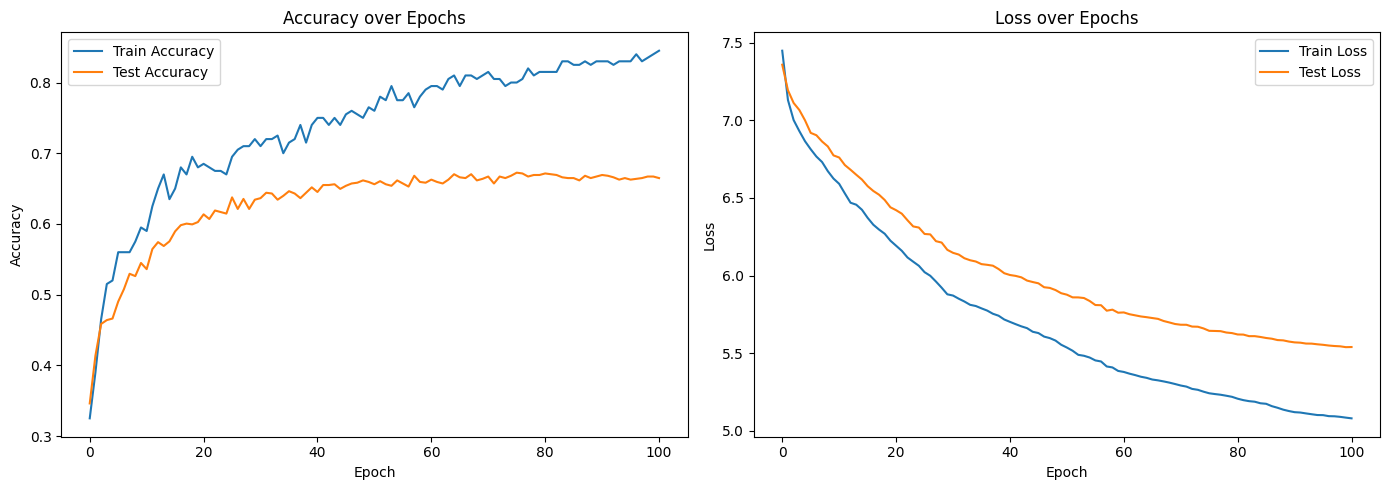


Final Test Accuracy: 0.6648


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_acc_history, label='Train Accuracy')
axes[0].plot(test_acc_history, label='Test Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy over Epochs')
axes[0].legend()

axes[1].plot(train_loss_history, label='Train Loss')
axes[1].plot(test_loss_history, label='Test Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].set_title('Loss over Epochs')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(SAVE, 'training_curves.png'))
plt.show()

print(f'\nFinal Test Accuracy: {test_acc_history[-1]:.4f}')